# 05 · Complex-valued ("quantum-inspired") knowledge-graph embeddings

**QGAI open notebooks · Track: Quantum Knowledge Graphs**

Knowledge graphs store facts as triples like *(Asha, manages, Ravi)*. Embedding models learn a vector per entity and relation
and score how plausible a triple is. Two classic models of the same size differ in one way:

| Model | Vectors | Score | Consequence |
|---|---|---|---|
| DistMult | real | $\sum_k e_s^k\, w_r^k\, e_o^k$ | symmetric: score(A, r, B) = score(B, r, A) **always** |
| ComplEx | complex | $\mathrm{Re}\sum_k e_s^k\, w_r^k\, \overline{e_o^k}$ | the complex conjugate breaks the symmetry |

Complex amplitudes and conjugation are the language of quantum states, which is why such models are called *quantum-inspired*.
**Everything here runs on ordinary classical hardware**; we include it because quantum representations motivate it, and because it is an honest example of
research ideas from quantum computing that pay off classically today.

Data: a synthetic company of 40 people with a symmetric relation (*colleague_of*: same manager) and an antisymmetric one (*manages*).

In [1]:
import numpy as np
import pennylane as qml
from pennylane import numpy as pnp
import matplotlib.pyplot as plt

SEED = 0
rng = np.random.default_rng(SEED)

## A 40-person org chart
One CEO, 3 directors, 9 managers, 27 staff. Each person except the CEO has one manager.

In [2]:
parent = {0: None}
nxt, level = 1, [0]
for _ in range(3):
    new = []
    for p in level:
        for _ in range(3):
            parent[nxt] = p; new.append(nxt); nxt += 1
    level = new
E = len(parent)
MANAGES, COLLEAGUE = 0, 1
manages = [(p, c) for c, p in parent.items() if p is not None]
colleague = [(a, b) for a in parent for b in parent if a != b and parent[a] is not None and parent[a] == parent[b]]
print(f"{E} people, {len(manages)} 'manages' facts, {len(colleague)} 'colleague_of' facts")

def split(seed, n_test=8):
    r = np.random.default_rng(seed)
    perm = r.permutation(len(manages))
    test_m = [manages[i] for i in perm[:n_test]]      # hide 8 'manages' facts
    train = [(s, MANAGES, o) for s, o in (manages[i] for i in perm[n_test:])] + [(s, COLLEAGUE, o) for s, o in colleague]
    return train, test_m

40 people, 39 'manages' facts, 78 'colleague_of' facts


## Models and training
Both models get the same budget: 32 real numbers per entity (DistMult: 32 real; ComplEx: 16 complex) and the same per relation.
For every training fact $(s, r, o)$ the model must rank the true $o$ above all other people **and** the true $s$ above all other people
(softmax cross-entropy in both directions, a standard KG training setup), trained with Adam.

In [3]:
D = 32

def scores_tails(params, model, s, r):
    """Score (s, r, every entity) -> array of shape (len(s), E)."""
    ent, rel = params[0], params[1]
    if model == "DistMult":
        return (ent[s] * rel[r]) @ ent.T
    h = D // 2
    er, ei = ent[:, :h], ent[:, h:]; rr, ri = rel[:, :h], rel[:, h:]
    sr, si, wr, wi = er[s], ei[s], rr[r], ri[r]
    # Re( e_s * w_r * conj(e_o) ) for every candidate tail o, in real arithmetic
    return (sr * wr - si * wi) @ er.T + (sr * wi + si * wr) @ ei.T

def scores_heads(params, model, r, o):
    """Score (every entity, r, o) -> array of shape (len(o), E)."""
    ent, rel = params[0], params[1]
    if model == "DistMult":
        return (ent[o] * rel[r]) @ ent.T
    h = D // 2
    er, ei = ent[:, :h], ent[:, h:]; rr, ri = rel[:, :h], rel[:, h:]
    orr, oi, wr, wi = er[o], ei[o], rr[r], ri[r]
    # Re( e_c * w_r * conj(e_o) ) for every candidate head c
    return (orr * wr + oi * wi) @ er.T + (oi * wr - orr * wi) @ ei.T

def xent(sc, true_idx):
    m = pnp.max(sc, axis=1, keepdims=True)
    logZ = pnp.log(pnp.sum(pnp.exp(sc - m), axis=1)) + m[:, 0]
    return pnp.mean(logZ - sc[np.arange(len(true_idx)), true_idx])

def train_model(model, train, seed):
    S = np.array([t[0] for t in train]); R = np.array([t[1] for t in train]); O = np.array([t[2] for t in train])
    def loss(e, r):
        return xent(scores_tails([e, r], model, S, R), O) + xent(scores_heads([e, r], model, R, O), S) + 1e-3 * (pnp.sum(e ** 2) + pnp.sum(r ** 2))
    init = np.random.default_rng(seed)
    params = [pnp.array(init.normal(0, 0.1, (E, D)), requires_grad=True), pnp.array(init.normal(0, 0.1, (2, D)), requires_grad=True)]
    opt = qml.AdamOptimizer(0.03)
    for _ in range(1500):
        params = opt.step(loss, *params)
    return [np.asarray(p) for p in params]

## Two tests on the hidden "manages" facts

1. **Direction:** for each hidden fact *(boss, manages, report)*, is the model more confident in it than in the reversed *(report, manages, boss)*? Ties count as half right.
2. **Predicting the hidden manager:** ask *(?, manages, report)* and rank all 40 people. We report mean reciprocal rank (MRR; 1.0 = always ranked first) and Hits@1, ignoring other known true answers.

In [4]:
def evaluate(params, model, train, test_m):
    known = set(train); right, rr, hits = 0.0, [], 0
    for s, o in test_m:
        f = float(scores_tails(params, model, np.array([s]), np.array([MANAGES]))[0, o])
        b = float(scores_tails(params, model, np.array([o]), np.array([MANAGES]))[0, s])
        right += 1.0 if f > b + 1e-9 else 0.5 if abs(f - b) <= 1e-9 else 0.0
        sc = np.asarray(scores_heads(params, model, np.array([MANAGES]), np.array([o])))[0].copy()
        for cand in range(E):
            if cand != s and (cand, MANAGES, o) in known: sc[cand] = -np.inf
        rank = 1 + int(np.sum(sc > sc[s])); rr.append(1 / rank); hits += rank == 1
    return dict(direction=right / len(test_m), mrr=float(np.mean(rr)), hits1=hits / len(test_m))

## Results over 5 random train/test splits
With only 8 hidden facts per split, a single split is too noisy, so we repeat everything on 5 splits.

5 splits; each: 109 training facts, 8 hidden 'manages' facts

model        direction correct            MRR         Hits@1
DistMult           50% ±   0%    0.136 ± 0.056       0% ±  0%
ComplEx            92% ±  15%    0.232 ± 0.064       8% ±  6%

random guessing: direction 50%, MRR about 0.107


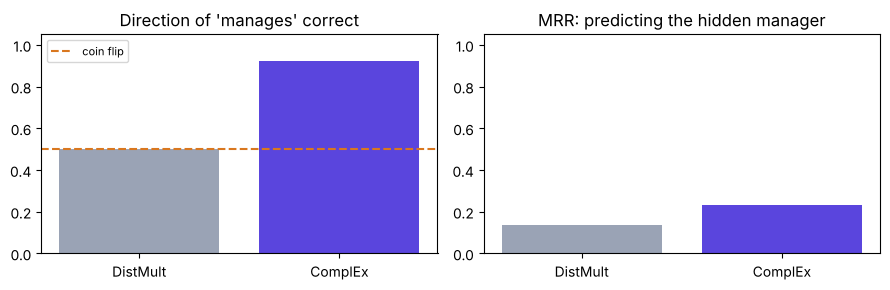

In [5]:
SPLITS = [0, 1, 2, 3, 4]
res = {"DistMult": [], "ComplEx": []}
for sp in SPLITS:
    train, test_m = split(sp)
    for model in res:
        res[model].append(evaluate(train_model(model, train, sp), model, train, test_m))
print(f"{len(SPLITS)} splits; each: {len(train)} training facts, {len(test_m)} hidden 'manages' facts\n")
print(f"{'model':9s} {'direction correct':>20s} {'MRR':>14s} {'Hits@1':>14s}")
summary = {}
for model, rows in res.items():
    d = np.array([r["direction"] for r in rows]); m = np.array([r["mrr"] for r in rows]); h = np.array([r["hits1"] for r in rows])
    summary[model] = (d.mean(), m.mean())
    print(f"{model:9s} {d.mean():>12.0%} ± {d.std():>4.0%} {m.mean():>8.3f} ± {m.std():.3f} {h.mean():>8.0%} ± {h.std():>3.0%}")
print(f"\nrandom guessing: direction 50%, MRR about {np.mean([1 / k for k in range(1, E + 1)]):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
models = list(res)
axes[0].bar(models, [summary[m][0] for m in models], color=["#9aa3b5", "#5a45dd"]); axes[0].axhline(0.5, color="#d9771f", ls="--", label="coin flip")
axes[0].set_ylim(0, 1.05); axes[0].set_title("Direction of 'manages' correct"); axes[0].legend(fontsize=8)
axes[1].bar(models, [summary[m][1] for m in models], color=["#9aa3b5", "#5a45dd"]); axes[1].set_ylim(0, 1.05)
axes[1].set_title("MRR: predicting the hidden manager")
plt.tight_layout(); plt.show()

## Reading the results

- **Direction:** DistMult *cannot* tell "A manages B" from "B manages A". Its score is mathematically symmetric, so it ties every time (exactly 50%). ComplEx gets the direction right about **92%** of the time on facts it never saw, averaged over 5 splits. This is the clearest effect in the notebook, and it follows directly from the complex conjugate.
- **Predicting a hidden manager:** ComplEx is better (MRR about 0.23 vs 0.14) but both are **modest**; random guessing scores about 0.11, and Hits@1 stays low. A 40-person graph with 31 remaining "manages" facts gives little to learn from. With identical parameter budgets, the gap comes from the representation, not model size.
- **This is not quantum computing.** It is a classical model whose design borrows the mathematics of quantum states. ComplEx is well established in the KG literature (Trouillon et al., 2016). The open QGAI question is whether richer *quantum* representations (density matrices for ambiguous entities, or circuits on real hardware) add anything beyond it.

**Try next:** a bigger graph; a second antisymmetric relation (e.g. *mentors*); noisy or missing colleague links; comparison with RotatE and TransE.